# 🚲 서울 따릉이 대여 수요 예측
### 수업에서 배운 내용으로 직접 만든 "최적 모델 자동 탐색" (AutoML 아이디어 구현)

- **팀원** : (이름·학번) / (이름·학번) / (이름·학번)
- **데이터** : UCI Machine Learning Repository, *Seoul Bike Sharing Demand* (2017.12 ~ 2018.11, 시간 단위 8,760행)
- **목표** : 날씨·시간 조건으로 따릉이 대여량을 예측한다. 이때 **변수 조합 × 정규화 방법 × 알고리즘·파라미터**를 `for`문으로 자동 탐색해 가장 좋은 모델을 찾는다.

**분석 질문**
- Q1. 따릉이는 언제 가장 많이 탈까? (시간대, 요일, 계절)
- Q2. 날씨 중 무엇이 대여량에 가장 큰 영향을 줄까?
- Q3. 이 변수들로 대여량을 얼마나 정확히 예측할 수 있을까? (교수님 기준: 회귀 R² 60% 이상 / 분류 정확도 80% 이상)

### 📚 배운 내용 활용표

| 단계 | 사용한 것 | 출처 | 위치 |
|---|---|---|---|
| 불러오기·탐색 | `read_csv`, `info`, `describe`, `isnull().sum()`, `value_counts` | 실습 | 2장 |
| 날짜 처리 | `pd.to_datetime`, `.dt` | 실습(슈퍼마켓 시간대별 매출) | 3장 |
| 범주형 변환 | `LabelEncoder`, `map` | 실습(타이타닉·라리가), 교재 6장 | 3장 |
| 파생변수 | `map(...).fillna(0)` | 실습(라리가) | 3장 |
| 시각화 | `groupby`, `unstack`, `boxplot`, `scatterplot`, `kdeplot` | 실습 | 4장 |
| 로그 정규화 | `np.log` | 실습 | 4장 |
| 구간 나누기(Binning) | `np.percentile` + 함수 + `map` | 교재 11장, 실습 | 5장 |
| 데이터 분할 | 훈련/검증/테스트 70/15/15 | 교재 11장 | 6장 |
| 단순→다중회귀 | `LinearRegression`, `coef_`, `r2_score`, `mean_squared_error` | 실습(라리가·weatherHistory) | 7장 |
| 로지스틱 회귀 | `LogisticRegression`, `predict_proba` | 실습(weatherHistory), 교재 6장 | 7장 |
| 스케일링 비교 | `StandardScaler`, `MinMaxScaler`, 스케일링 전/후 KNN | 실습(wine KNN), 교재 9·11장 | 7·8장 |
| 결정트리 | `DecisionTreeRegressor/Classifier`, `max_depth`, `feature_importances_` | 교재 7장 | 8장 |
| SVM | `SVR`, `SVC`, `kernel`, `C` | 교재 8장 | 8장 |
| KNN | `KNeighborsRegressor/Classifier`, `n_neighbors`, `weights` | 교재 9장, 실습 | 8장 |
| SGD | `SGDRegressor`, `SGDClassifier`, `alpha`, `time.time()` | 교재 10장 | 8장 |
| 자동 탐색 | `for`문으로 파라미터를 바꿔 가며 점수 비교 | 교재 9장(최적 K 찾기) | 8장 |
| 과대적합 확인 | 훈련 점수 vs 검증 점수 | 교재 11장 | 8장 |
| 평가 | `confusion_matrix`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score` | 교재 12장 | 8장 |
| 시연 | 조건 입력 → 예측 | 실습(weatherHistory 샘플 예측) | 9장 |

## 1. 준비

**하는 일** : 분석에 필요한 라이브러리를 불러온다

**설명**
- `numpy`, `pandas` : 데이터 계산·표 처리
- `matplotlib`, `seaborn` : 그래프
- `sklearn` : 데이터 나누기, 스케일링, 모델(회귀·분류), 평가 지표
- `time` : 자동 탐색에 걸린 시간 측정 (교재 10장)

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression, SGDRegressor, SGDClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.svm import SVR, SVC
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

## 2. 데이터 불러오기와 탐색

**하는 일** : UCI 저장소에서 따릉이 데이터를 바로 읽어 온다

**설명**
- 파일을 업로드하지 않아도 주소만으로 읽을 수 있다
- `encoding='cp1252'` : 컬럼 이름에 `°C` 기호가 있어서 기본 방식(utf-8)으로 읽으면 오류가 난다

In [2]:
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00560/SeoulBikeData.csv'
df = pd.read_csv(url, encoding='cp1252')
df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


**하는 일** : 컬럼 이름을 짧은 영어 이름으로 바꾸고 자료형을 확인한다

**설명**
- 원래 이름은 `Temperature(°C)`처럼 길고 특수문자가 있어서 코드에 쓰기 불편하다
- 순서대로 날짜, 대여량, 시간, 기온, 습도, 풍속, 시정, 이슬점, 일사량, 강수량, 적설량, 계절, 공휴일, 운영일 여부

In [3]:
df.columns = ['Date', 'Count', 'Hour', 'Temp', 'Humidity', 'Wind', 'Visibility',
              'Dew', 'Solar', 'Rain', 'Snow', 'Season', 'Holiday', 'Func']
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Date        8760 non-null   object 
 1   Count       8760 non-null   int64  
 2   Hour        8760 non-null   int64  
 3   Temp        8760 non-null   float64
 4   Humidity    8760 non-null   int64  
 5   Wind        8760 non-null   float64
 6   Visibility  8760 non-null   int64  
 7   Dew         8760 non-null   float64
 8   Solar       8760 non-null   float64
 9   Rain        8760 non-null   float64
 10  Snow        8760 non-null   float64
 11  Season      8760 non-null   object 
 12  Holiday     8760 non-null   object 
 13  Func        8760 non-null   object 
dtypes: float64(6), int64(4), object(4)
memory usage: 958.3+ KB


**하는 일** : 결측치와 기초 통계를 확인한다

**설명**
- `isnull().sum()` : 열마다 비어 있는 값의 개수 → 따릉이 데이터는 **결측치가 0개**라서 `fillna`로 채울 필요가 없다
- `describe()` : 평균, 최솟값, 최댓값 등으로 이상한 값이 없는지 본다

In [4]:
print(df.isnull().sum())
df.describe()

Date          0
Count         0
Hour          0
Temp          0
Humidity      0
Wind          0
Visibility    0
Dew           0
Solar         0
Rain          0
Snow          0
Season        0
Holiday       0
Func          0
dtype: int64


,Count,Hour,Temp,Humidity,Wind,Visibility,Dew,Solar,Rain,Snow
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068
std,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000
25%,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000
50%,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000
75%,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000


## 3. 전처리

**하는 일** : 따릉이를 운영하지 않은 날을 확인한다

**설명**
- `Func`가 `No`인 날은 대여 서비스를 하지 않은 날이다
- 이런 날은 대여량이 전부 0이라, 날씨와 상관없이 0이 나온다 → 예측에 방해가 된다

In [5]:
print(df['Func'].value_counts())
print(df.groupby('Func')['Count'].sum())

Func
Yes    8465
No      295
Name: count, dtype: int64
Func
No           0
Yes    6172314
Name: Count, dtype: int64


**하는 일** : 운영한 날만 남기고 필요 없는 열을 지운다

**설명**
- `df[df['Func'] == 'Yes']` : 운영한 날만 고른다
- `drop` : 이제 전부 `Yes`라 의미가 없어진 `Func` 열을 지운다

In [6]:
df = df[df['Func'] == 'Yes']
df = df.drop(columns=['Func'])
print(df.shape)

(8465, 13)


**하는 일** : 날짜에서 요일과 주말 여부를 뽑는다

**설명**
- 실습(슈퍼마켓)에서 `to_datetime` → `.dt.hour`로 '몇 시'를 뽑은 방식과 같다. 여기서는 `.dt.dayofweek`로 요일을 뽑는다
- 날짜가 `01/12/2017`(일/월/년) 형식이라 `format='%d/%m/%Y'`로 알려 준다
- `Weekday` : 월요일 0 ~ 일요일 6, `Weekend` : 토·일이면 1

In [7]:
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')
df['Weekday'] = df['Date'].dt.dayofweek
df['Weekend'] = (df['Weekday'] >= 5).astype(int)
df[['Date', 'Weekday', 'Weekend']].head()

,Date,Weekday,Weekend
0,2017-12-01,4,0
1,2017-12-01,4,0
2,2017-12-01,4,0
3,2017-12-01,4,0
4,2017-12-01,4,0


**하는 일** : `LabelEncoder`로 계절을 숫자로 바꾸면 어떻게 되는지 확인한다

**설명**
- `LabelEncoder`는 **알파벳 순서**로 번호를 붙인다 (Autumn=0, Spring=1, Summer=2, Winter=3)
- 그러면 계절의 실제 순서(봄→여름→가을→겨울)와 맞지 않는다 → 다음 셀에서 `map`으로 번호를 직접 정한다

In [8]:
le = LabelEncoder()
print(le.fit_transform(['Spring', 'Summer', 'Autumn', 'Winter']))
print(le.classes_)

[1 2 0 3]
['Autumn' 'Spring' 'Summer' 'Winter']


**하는 일** : 계절과 공휴일을 `map`으로 숫자로 바꾼다

**설명**
- 실습(타이타닉 성별, 라리가 포지션)과 같은 방식
- 계절 : 봄 0, 여름 1, 가을 2, 겨울 3 / 공휴일 : 아니면 0, 공휴일이면 1

In [9]:
df['Season'] = df['Season'].map({'Spring': 0, 'Summer': 1, 'Autumn': 2, 'Winter': 3})
df['Holiday'] = df['Holiday'].map({'No Holiday': 0, 'Holiday': 1})
print(df['Season'].value_counts())
print(df['Holiday'].value_counts())

Season
1    2208
3    2160
0    2160
2    1937
Name: count, dtype: int64
Holiday
0    8057
1     408
Name: count, dtype: int64


**하는 일** : 파생변수(출퇴근 시간 여부, 비 온 시간 여부)를 만든다

**설명**
- `Commute` : 7~9시, 17~19시이면 1
  - 사전에 없는 시간은 `map` 결과가 비어 있게(NaN) 되므로 `fillna(0)`으로 0을 채운다 → 실습(라리가 `Position`)과 같은 방식
- `Rainy` : 비가 조금이라도 왔으면 1
- 시간과 대여량은 직선 관계가 아니라서(출퇴근에 튀어 오름), 선형회귀가 이 패턴을 잡도록 도와준다

In [10]:
commute = {7: 1, 8: 1, 9: 1, 17: 1, 18: 1, 19: 1}
df['Commute'] = df['Hour'].map(commute).fillna(0).astype(int)
df['Rainy'] = (df['Rain'] > 0).astype(int)
df[['Hour', 'Commute', 'Rain', 'Rainy']].head(10)

,Hour,Commute,Rain,Rainy
0,0,0,0.0,0
1,1,0,0.0,0
2,2,0,0.0,0
3,3,0,0.0,0
4,4,0,0.0,0
5,5,0,0.0,0
6,6,0,0.0,0
7,7,1,0.0,0
8,8,1,0.0,0
9,9,1,0.0,0


## 4. 시각화로 살펴보기 (Q1·Q2)

**하는 일** : 시간대별 평균 대여량을 막대그래프로 그린다

**설명**
- `groupby('Hour')` : 시간대별로 묶어서 평균을 낸다
- 출근(8시)과 퇴근(18시)에 크게 튀어 오르는지 본다

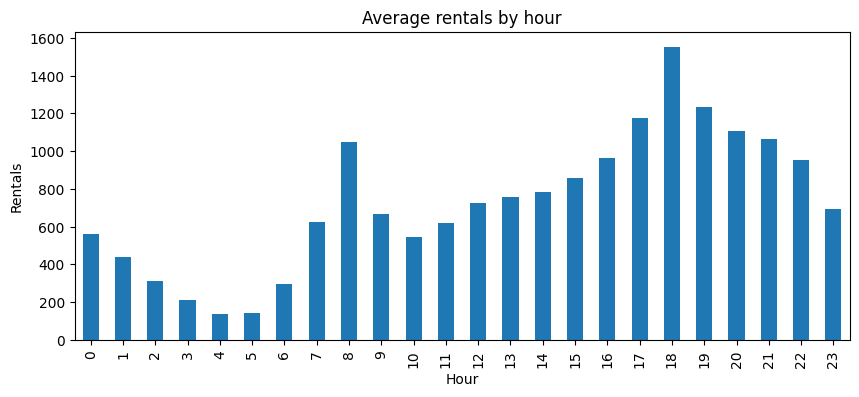

In [11]:
hour_mean = df.groupby('Hour')['Count'].mean()
hour_mean.plot(kind='bar', figsize=(10, 4))
plt.title('Average rentals by hour')
plt.xlabel('Hour')
plt.ylabel('Rentals')
plt.show()

**하는 일** : 평일과 주말의 시간대별 대여량을 비교한다

**설명**
- `groupby(['Hour', 'Weekend']).mean().unstack()` : 시간 × 주말 여부 표를 만든다 (실습의 `unstack`)
- 평일은 출퇴근 두 봉우리, 주말은 낮 시간 한 봉우리가 나오는지 본다

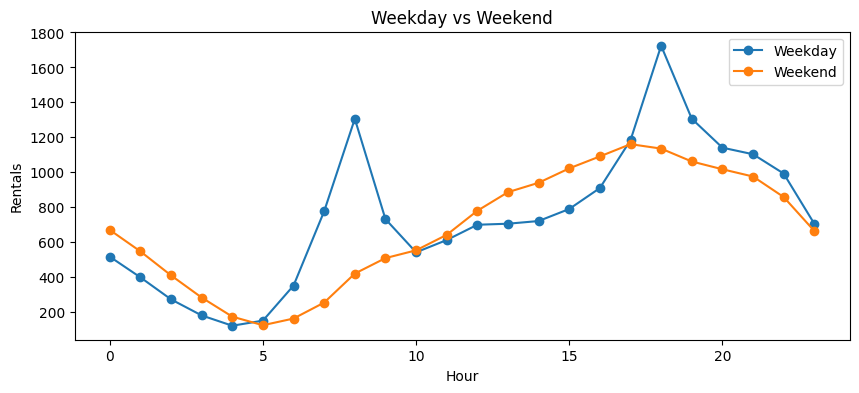

In [12]:
week = df.groupby(['Hour', 'Weekend'])['Count'].mean().unstack()
week.columns = ['Weekday', 'Weekend']
week.plot(marker='o', figsize=(10, 4))
plt.title('Weekday vs Weekend')
plt.xlabel('Hour')
plt.ylabel('Rentals')
plt.show()

**하는 일** : 계절별 대여량 분포를 상자그림으로 본다

**설명**
- 상자 가운데 선이 중앙값, 상자 높이가 흩어진 정도
- 겨울에 대여량이 크게 줄어드는지 본다

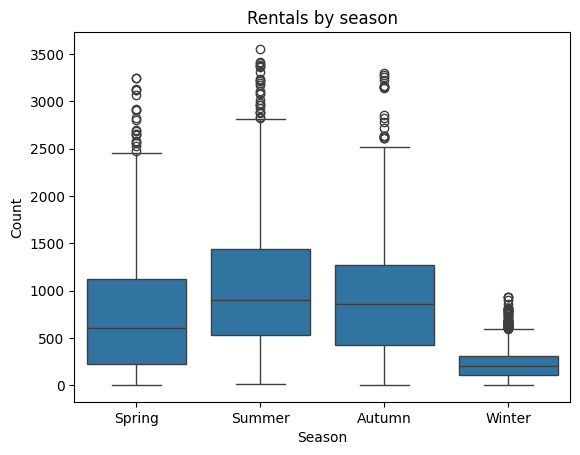

In [13]:
sns.boxplot(data=df, x='Season', y='Count')
plt.xticks([0, 1, 2, 3], ['Spring', 'Summer', 'Autumn', 'Winter'])
plt.title('Rentals by season')
plt.show()

**하는 일** : 기온과 대여량의 관계를 산점도로 본다 (비 온 시간은 색을 다르게)

**설명**
- 기온이 오를수록 대여량이 늘어나는지, 너무 더우면 다시 줄어드는지 본다
- `hue='Rainy'` : 비 온 시간(1)은 기온과 상관없이 대여량이 낮은지 본다

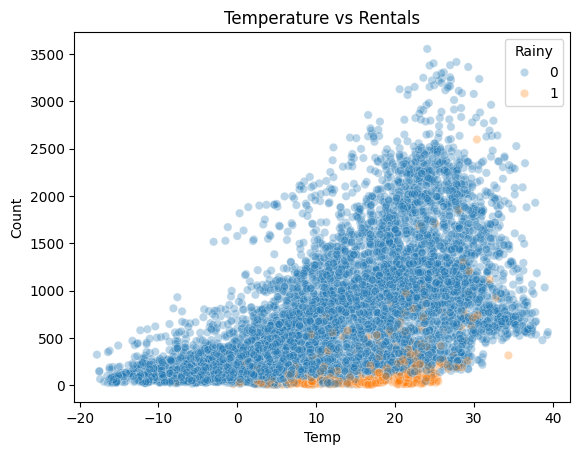

In [14]:
sns.scatterplot(data=df, x='Temp', y='Count', hue='Rainy', alpha=0.3)
plt.title('Temperature vs Rentals')
plt.show()

**하는 일** : 대여량 분포와 로그 변환 후 분포를 비교한다

**설명**
- 실습의 `np.log` 정규화 + `kdeplot`과 같은 방식
- 대여량은 0 근처에 몰려 있고 오른쪽으로 길게 늘어진(치우친) 분포다
- `np.log(Count + 1)` : 0에는 로그를 쓸 수 없어서 1을 더한 뒤 로그를 씌운다 → 분포가 덜 치우친다

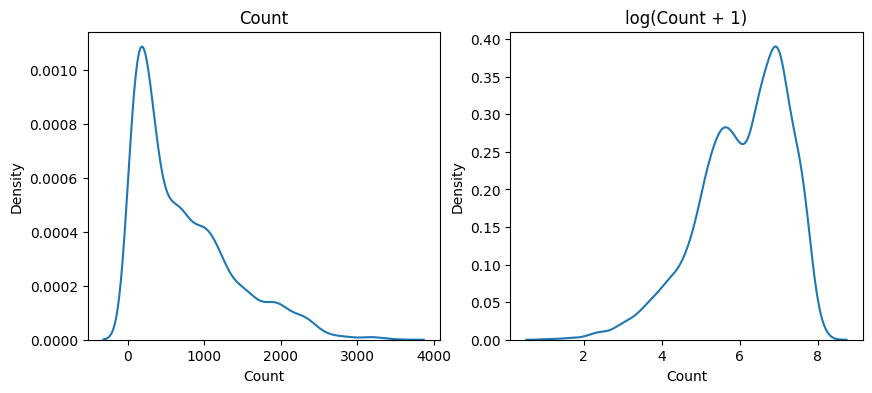

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.kdeplot(df['Count'], ax=ax[0])
ax[0].set_title('Count')
sns.kdeplot(np.log(df['Count'] + 1), ax=ax[1])
ax[1].set_title('log(Count + 1)')
plt.show()

## 5. 분류용 정답 만들기 (구간 나누기, 교재 11장)

**하는 일** : 대여량을 3단계(적음 / 보통 / 많음)로 나눈다

**설명**
- `np.percentile` : 하위 33.3%, 66.7% 위치의 값을 구한다 → 세 그룹의 개수가 거의 같아진다
- `demand_level` 함수로 단계를 정하고 `map`으로 모든 행에 적용한다
- 3단계로 나누면 12장의 혼동행렬(3×3)과 정밀도·재현율(`average='macro'`)을 쓸 수 있다

In [16]:
cut1, cut2 = np.percentile(df['Count'], [33.3, 66.7])
print('기준값:', cut1, cut2)

def demand_level(count):
    if count < cut1:
        return 0      # 적음
    elif count < cut2:
        return 1      # 보통
    else:
        return 2      # 많음

df['Level'] = df['Count'].map(demand_level)
print(df['Level'].value_counts())

기준값: 285.0 896.0
Level
1    2831
2    2820
0    2814
Name: count, dtype: int64


## 6. 훈련 / 검증 / 테스트 나누기 (교재 11장)

**하는 일** : 데이터를 훈련 70%, 검증 15%, 테스트 15%로 나눈다

**설명**
- **훈련** : 모델 학습용
- **검증** : 여러 모델 중 가장 좋은 것을 **고르는** 용도 (자동 탐색에서 사용)
- **테스트** : 고른 모델을 **마지막에 한 번만** 평가하는 용도 → 고를 때 테스트를 쓰면 시험 문제를 미리 보고 고른 셈이 된다
- `train_test_split`을 두 번 쓴다 : 70 / 30 → 30을 다시 반반(15 / 15)

In [17]:
all_features = ['Hour', 'Temp', 'Humidity', 'Wind', 'Visibility', 'Dew', 'Solar',
                'Rain', 'Snow', 'Season', 'Holiday', 'Weekend', 'Commute', 'Rainy']
X = df[all_features]
y = df['Count']        # 회귀 정답 : 대여량
y_cls = df['Level']    # 분류 정답 : 수요 단계

X_train, X_rest, y_train, y_rest, c_train, c_rest = train_test_split(
    X, y, y_cls, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test, c_val, c_test = train_test_split(
    X_rest, y_rest, c_rest, test_size=0.5, random_state=42)

print('훈련', len(X_train), '/ 검증', len(X_val), '/ 테스트', len(X_test))

훈련 5925 / 검증 1270 / 테스트 1270


## 7. 기본 모델 : 선형회귀와 로지스틱 회귀

**하는 일** : 변수를 하나씩 늘려 가며 선형회귀 점수를 비교한다

**설명**
- 실습(라리가)에서 단순회귀 → 다중회귀로 변수를 늘린 방식과 같다
- `feature_sets` : 비교할 변수 조합 5개. 8장 자동 탐색에서도 그대로 쓴다
- 교수님 말씀 : "특징을 다 쓴다고 정확도가 높아지는 것은 아님 → 최적의 조합 찾기"
- RMSE = `mean_squared_error`의 제곱근 → "평균적으로 몇 대 틀리는지"

In [18]:
feature_sets = {
    'temp':         ['Temp'],
    'weather':      ['Temp', 'Humidity', 'Wind', 'Rain', 'Snow', 'Solar'],
    'weather+time': ['Temp', 'Humidity', 'Wind', 'Rain', 'Snow', 'Solar',
                     'Hour', 'Season', 'Holiday', 'Weekend'],
    'w+t+derived':  ['Temp', 'Humidity', 'Wind', 'Rain', 'Snow', 'Solar',
                     'Hour', 'Season', 'Holiday', 'Weekend', 'Commute', 'Rainy'],
    'all':          all_features,
}

for name in feature_sets:
    cols = feature_sets[name]
    lr = LinearRegression()
    lr.fit(X_train[cols], y_train)
    pred = lr.predict(X_val[cols])
    r2 = r2_score(y_val, pred)
    rmse = np.sqrt(mean_squared_error(y_val, pred))
    print(f'{name:14s}  R2 = {r2:.3f}   RMSE = {rmse:.0f}대')

temp            R2 = 0.330   RMSE = 518대
weather         R2 = 0.437   RMSE = 475대
weather+time    R2 = 0.518   RMSE = 439대
w+t+derived     R2 = 0.601   RMSE = 400대
all             R2 = 0.603   RMSE = 399대


**하는 일** : 회귀계수(`coef_`)를 보고 각 변수가 대여량에 주는 영향을 해석한다 (Q2)

**설명**
- 계수가 +이면 그 변수가 1 늘 때 대여량이 그만큼 늘고, -이면 줄어든다
- 예 : `Temp`가 +28이면 "기온 1도 상승 → 대여 약 28대 증가"

In [19]:
base_cols = feature_sets['w+t+derived']
lr = LinearRegression()
lr.fit(X_train[base_cols], y_train)
print(pd.Series(lr.coef_, index=base_cols).round(1))

Temp         30.8
Humidity     -6.2
Wind          3.4
Rain        -19.2
Snow          9.4
Solar       -59.1
Hour         26.6
Season      -28.6
Holiday    -133.6
Weekend     -91.1
Commute     379.5
Rainy      -494.2
dtype: float64


**하는 일** : 선형회귀의 한계를 확인한다

**설명**
- 대여량은 0보다 작을 수 없는데, 선형회귀는 음수를 예측하기도 한다
- 시간·기온과 대여량이 직선 관계가 아니기 때문 → 결정트리, KNN 같은 다른 알고리즘이 필요한 이유

In [20]:
pred = lr.predict(X_val[base_cols])
print('음수로 예측한 개수 :', (pred < 0).sum(), '/', len(pred))

음수로 예측한 개수 : 118 / 1270


**하는 일** : 로지스틱 회귀로 수요 단계(적음/보통/많음)를 분류한다

**설명**
- 실습(weatherHistory)에서 기온·습도·풍속으로 강수 형태를 분류한 방식과 같다
- 단위가 다른 변수(도, %, m/s)를 같은 기준으로 맞추려고 `StandardScaler`를 쓴다
  - `fit_transform`은 훈련 데이터에만, 검증 데이터는 `transform`만 한다
- `predict_proba` : 단계별 확률 (적음, 보통, 많음 순)

In [21]:
base_scaler = StandardScaler()
Xtr_s = base_scaler.fit_transform(X_train[base_cols])
Xva_s = base_scaler.transform(X_val[base_cols])

logi = LogisticRegression(max_iter=1000)
logi.fit(Xtr_s, c_train)
print('검증 정확도 :', round(logi.score(Xva_s, c_val), 3))
print(logi.predict_proba(Xva_s[:5]).round(2))

검증 정확도 : 0.706
[[0.06 0.53 0.41]
 [0.87 0.13 0.  ]
 [0.04 0.32 0.64]
 [0.   0.07 0.93]
 [0.28 0.65 0.06]]


**하는 일** : 스케일링 전과 후의 KNN 정확도를 비교한다

**설명**
- 실습(wine)에서 KNN을 스케일링 전/후로 비교한 방식과 같다
- KNN은 '거리'로 이웃을 찾기 때문에, 숫자가 큰 변수(예: 시정 0~2000)가 거리를 독차지한다 → 스케일링이 중요하다

In [22]:
knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(X_train[base_cols], c_train)
print('스케일링 전 :', round(knn.score(X_val[base_cols], c_val), 3))

knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(Xtr_s, c_train)
print('스케일링 후 :', round(knn.score(Xva_s, c_val), 3))

스케일링 전 : 0.786
스케일링 후 : 0.816


## 8. 최적 모델 자동 탐색 (AutoML 아이디어를 직접 구현)

교재 9장에서 `for k in range(1, 101)`로 K를 바꿔 가며 가장 좋은 K를 찾았다.
여기서는 바꾸는 대상을 **세 가지**로 늘린다.

1. **변수 조합** : `feature_sets` 5개
2. **스케일링** : 없음 / `StandardScaler` / `MinMaxScaler`
3. **알고리즘 + 파라미터** : 선형회귀, 결정트리(`max_depth`), KNN(`n_neighbors`, `weights`), SVM(`C`, `kernel`), SGD(`alpha`)

모든 조합을 학습해 **검증 점수**를 기록하고, 가장 높은 조합을 고른 뒤 **테스트 데이터로 한 번만** 최종 평가한다.
AutoML 라이브러리를 쓰지 않고 수업에서 배운 `for`문과 모델만으로 만들었다.

**하는 일** : 스케일링 방법을 이름으로 고를 수 있는 함수를 만든다

**설명**
- `'none'` : 그대로 / `'standard'` : 평균 0·표준편차 1 / `'minmax'` : 0~1 사이 (교재 11장)
- 훈련 데이터로만 `fit`하고, 평가 데이터는 `transform`만 한다
- 나중에 시연에서 같은 방식으로 바꾸려고 scaler도 함께 돌려준다

In [23]:
def scale_data(scaler_name, X_tr, X_ev):
    if scaler_name == 'none':
        return X_tr, X_ev, None
    if scaler_name == 'standard':
        scaler = StandardScaler()
    else:
        scaler = MinMaxScaler()
    return scaler.fit_transform(X_tr), scaler.transform(X_ev), scaler

scaler_names = ['none', 'standard', 'minmax']

# 스케일링을 안 하면 학습이 잘 안 되거나 매우 느린 알고리즘 (교재 10장 알고리즘 특성 표)
needs_scaling = ['Logistic', 'SVR', 'SVC', 'SGD']

### 8-1. 회귀 : 대여량 예측

**하는 일** : 비교할 회귀 모델 후보를 만드는 함수

**설명**
- `for`문으로 파라미터를 바꿔 가며 후보를 추가한다 (교재 9장 최적 K 찾기 방식)
- 함수를 부를 때마다 **새 모델**을 만들어서, 앞에서 학습한 결과가 섞이지 않게 한다
- 이름의 첫 단어(예: `Tree`)가 알고리즘 이름이다

In [24]:
def make_regressors():
    models = []
    models.append(('Linear', LinearRegression()))
    for d in [3, 5, 10, 15]:
        models.append((f'Tree depth={d}', DecisionTreeRegressor(max_depth=d, random_state=42)))
    for k in [5, 10, 20]:
        for w in ['uniform', 'distance']:
            models.append((f'KNN k={k} {w}', KNeighborsRegressor(n_neighbors=k, weights=w)))
    for c in [10, 100]:
        models.append((f'SVR rbf C={c}', SVR(kernel='rbf', C=c)))
    for a in [0.0001, 0.01]:
        models.append((f'SGD alpha={a}', SGDRegressor(alpha=a, max_iter=1000, random_state=42)))
    return models

print('회귀 후보 모델 수 :', len(make_regressors()))

회귀 후보 모델 수 : 15


**하는 일** : 변수 조합 × 스케일링 × 모델을 모두 학습하고 점수를 기록한다 (자동 탐색)

**설명**
- `for`문 3개를 겹쳐서 모든 조합을 차례로 돌린다
- 조합마다 **훈련 R²**와 **검증 R²**를 기록한다 → 둘의 차이가 크면 과대적합 (교재 11장)
- SVR이 있어서 몇 분 걸릴 수 있다. `time.time()`으로 걸린 시간을 잰다 (교재 10장)

In [25]:
reg_results = []
start = time.time()

for fs_name in feature_sets:
    cols = feature_sets[fs_name]
    for sc_name in scaler_names:
        Xtr, Xva, _ = scale_data(sc_name, X_train[cols], X_val[cols])
        for m_name, model in make_regressors():
            algo = m_name.split()[0]
            if sc_name == 'none' and algo in needs_scaling:
                continue
            model.fit(Xtr, y_train)
            reg_results.append({'features': fs_name, 'scaler': sc_name,
                                'model': m_name, 'algorithm': algo,
                                'train_R2': r2_score(y_train, model.predict(Xtr)),
                                'val_R2': r2_score(y_val, model.predict(Xva))})

reg_df = pd.DataFrame(reg_results)
print(f'{len(reg_df)}개 조합 탐색 완료, {time.time() - start:.0f}초')

205개 조합 탐색 완료, 134초


**하는 일** : 검증 R²가 가장 높은 조합을 찾는다

**설명**
- `argmax()` : 가장 큰 값이 몇 번째 줄인지 알려 준다
- 훈련 R²와 검증 R² 차이로 과대적합 여부를 확인한다
- 주의 : KNN `weights='distance'`는 훈련 데이터를 예측할 때 자기 자신과의 거리가 0이라 **훈련 점수가 항상 1.0**이 나온다 → 이 경우 차이만으로 과대적합을 판단하기 어렵다. 그래서 모델은 **검증 점수**로 고르고, 마지막에 테스트 점수로 다시 확인한다

In [26]:
best_r = reg_df.iloc[reg_df['val_R2'].argmax()]
print(best_r)
print('훈련-검증 차이 :', round(best_r['train_R2'] - best_r['val_R2'], 3))

features          w+t+derived
scaler                 minmax
model        KNN k=5 distance
algorithm                 KNN
train_R2                  1.0
val_R2               0.874375
Name: 155, dtype: object
훈련-검증 차이 : 0.126


**하는 일** : 알고리즘별 최고 검증 R²를 교수님 기준선과 함께 그린다

**설명**
- `groupby('algorithm')['val_R2'].max()` : 알고리즘마다 가장 좋았던 점수
- 주황 점선 60% = 쓸 만한 수준, 빨간 점선 70% = 실제로 쓸 수 있는 수준 (교수님 기준)

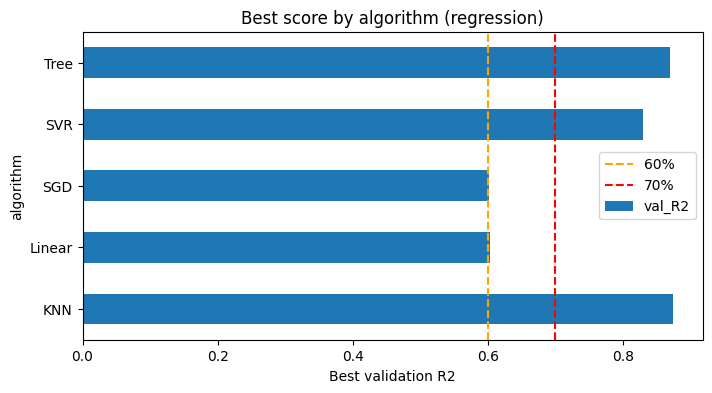

In [27]:
algo_best = reg_df.groupby('algorithm')['val_R2'].max()
algo_best.plot(kind='barh', figsize=(8, 4))
plt.axvline(0.6, color='orange', linestyle='--', label='60%')
plt.axvline(0.7, color='red', linestyle='--', label='70%')
plt.xlabel('Best validation R2')
plt.title('Best score by algorithm (regression)')
plt.legend()
plt.show()

**하는 일** : 변수 조합별 최고 검증 R²를 비교한다

**설명**
- 변수를 많이 쓸수록 항상 좋아지는지, 아니면 적당한 조합이 더 좋은지 확인한다 ("최적의 조합 찾기")

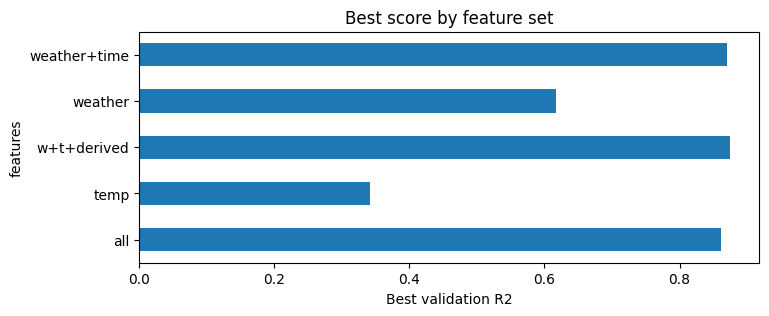

In [28]:
fs_best = reg_df.groupby('features')['val_R2'].max()
fs_best.plot(kind='barh', figsize=(8, 3))
plt.xlabel('Best validation R2')
plt.title('Best score by feature set')
plt.show()

**하는 일** : 찾은 최적 조합을 다시 학습해 **테스트 데이터로 최종 평가**한다

**설명**
- 자동 탐색에서 테스트 데이터는 한 번도 쓰지 않았다 → 처음 보는 데이터에서의 진짜 실력
- `dict(make_regressors())` : 모델 이름으로 같은 설정의 새 모델을 꺼낸다

In [29]:
best_cols_r = feature_sets[best_r['features']]
Xtr, Xte, best_reg_scaler = scale_data(best_r['scaler'], X_train[best_cols_r], X_test[best_cols_r])

best_reg = dict(make_regressors())[best_r['model']]
best_reg.fit(Xtr, y_train)
pred_test = best_reg.predict(Xte)

print('최적 모델 :', best_r['model'], '/', best_r['features'], '/', best_r['scaler'])
print('테스트 R2   :', round(r2_score(y_test, pred_test), 3))
print('테스트 MSE  :', round(mean_squared_error(y_test, pred_test)))
print('테스트 RMSE :', round(np.sqrt(mean_squared_error(y_test, pred_test))), '대')

최적 모델 : KNN k=5 distance / w+t+derived / minmax
테스트 R2   : 0.859
테스트 MSE  : 56647
테스트 RMSE : 238 대


**하는 일** : 예측값과 실제값을 산점도로 비교한다

**설명**
- 빨간 점선 위에 있을수록 정확하게 맞힌 것
- 어디에서 많이 틀리는지(대여량이 아주 많은 시간 등) 보고 한계를 설명한다

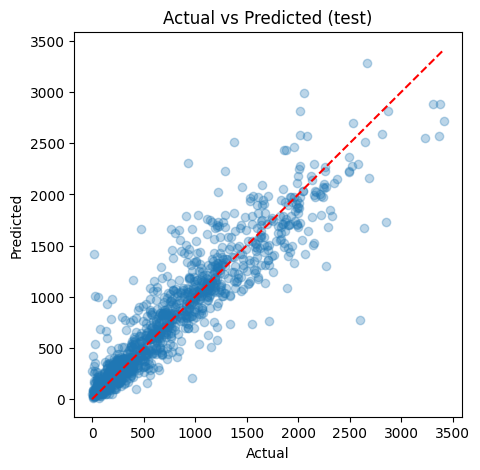

In [30]:
plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred_test, alpha=0.3)
plt.plot([0, y_test.max()], [0, y_test.max()], 'r--')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted (test)')
plt.show()

**하는 일** : 자동 탐색에서 가장 좋았던 **결정트리**로 변수 중요도를 본다 (교재 7장)

**설명**
- KNN은 변수 중요도를 알려 주지 않는다 → 점수가 비슷하게 높았던 결정트리로 중요도를 확인한다
- `feature_importances_` : 예측에 각 변수가 얼마나 쓰였는지 (합이 1)
- Q2(어떤 날씨가 가장 중요한가)에 대한 답이 된다

결정트리 최고 : Tree depth=15 / w+t+derived / 검증 R2 0.871


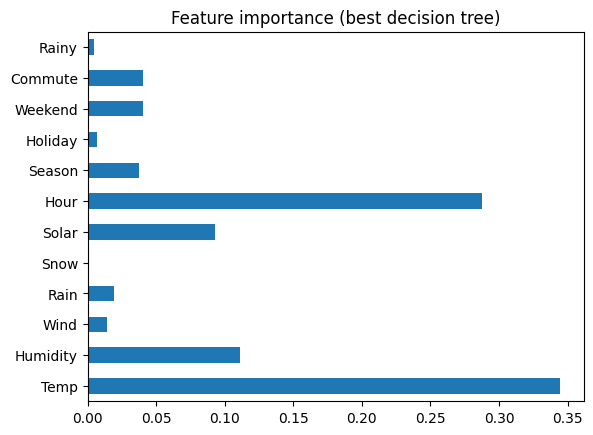

In [31]:
tree_rows = reg_df[reg_df['algorithm'] == 'Tree']
best_t = tree_rows.iloc[tree_rows['val_R2'].argmax()]
print('결정트리 최고 :', best_t['model'], '/', best_t['features'], '/ 검증 R2', round(best_t['val_R2'], 3))

tree_cols = feature_sets[best_t['features']]
Xtr, Xva, _ = scale_data(best_t['scaler'], X_train[tree_cols], X_val[tree_cols])
tree = dict(make_regressors())[best_t['model']]
tree.fit(Xtr, y_train)

importance = pd.Series(tree.feature_importances_, index=tree_cols)
importance.plot(kind='barh')
plt.title('Feature importance (best decision tree)')
plt.show()

### 8-2. 분류 : 수요 단계(적음 / 보통 / 많음) 예측

**하는 일** : 비교할 분류 모델 후보를 만드는 함수

**설명**
- 회귀와 같은 방식. 로지스틱 회귀(`C`), 결정트리, KNN, SVC(`kernel`), SGD
- `SGDClassifier(loss='log_loss')` : 교재의 `loss='log'`가 최신 sklearn에서 이름이 바뀐 것

In [32]:
def make_classifiers():
    models = []
    for c in [0.1, 1, 10]:
        models.append((f'Logistic C={c}', LogisticRegression(C=c, max_iter=1000)))
    for d in [3, 5, 10, 15]:
        models.append((f'Tree depth={d}', DecisionTreeClassifier(max_depth=d, random_state=42)))
    for k in [5, 10, 20]:
        for w in ['uniform', 'distance']:
            models.append((f'KNN k={k} {w}', KNeighborsClassifier(n_neighbors=k, weights=w)))
    for kernel in ['linear', 'rbf']:
        models.append((f'SVC {kernel}', SVC(kernel=kernel)))
    for a in [0.0001, 0.01]:
        models.append((f'SGD alpha={a}', SGDClassifier(loss='log_loss', alpha=a, max_iter=1000, random_state=42)))
    return models

print('분류 후보 모델 수 :', len(make_classifiers()))

분류 후보 모델 수 : 17


**하는 일** : 분류 자동 탐색 (회귀와 같은 구조, 점수만 정확도로)

**설명**
- 정답이 3단계 중 하나라서 점수는 `accuracy_score`(정확도)를 쓴다

In [33]:
cls_results = []
start = time.time()

for fs_name in feature_sets:
    cols = feature_sets[fs_name]
    for sc_name in scaler_names:
        Xtr, Xva, _ = scale_data(sc_name, X_train[cols], X_val[cols])
        for m_name, model in make_classifiers():
            algo = m_name.split()[0]
            if sc_name == 'none' and algo in needs_scaling:
                continue
            model.fit(Xtr, c_train)
            cls_results.append({'features': fs_name, 'scaler': sc_name,
                                'model': m_name, 'algorithm': algo,
                                'train_acc': accuracy_score(c_train, model.predict(Xtr)),
                                'val_acc': accuracy_score(c_val, model.predict(Xva))})

cls_df = pd.DataFrame(cls_results)
print(f'{len(cls_df)}개 조합 탐색 완료, {time.time() - start:.0f}초')

best_c = cls_df.iloc[cls_df['val_acc'].argmax()]
print(best_c)

220개 조합 탐색 완료, 82초
features           w+t+derived
scaler                  minmax
model        KNN k=20 distance
algorithm                  KNN
train_acc                  1.0
val_acc               0.838583
Name: 171, dtype: object


**하는 일** : 알고리즘별 최고 검증 정확도를 교수님 기준선(80%)과 함께 그린다

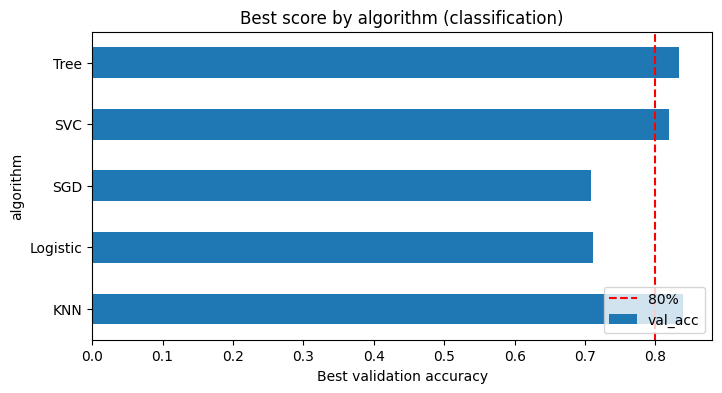

In [34]:
cls_df.groupby('algorithm')['val_acc'].max().plot(kind='barh', figsize=(8, 4))
plt.axvline(0.8, color='red', linestyle='--', label='80%')
plt.xlabel('Best validation accuracy')
plt.title('Best score by algorithm (classification)')
plt.legend(loc='lower right')
plt.show()

**하는 일** : 최적 분류 모델을 테스트 데이터로 평가한다 (교재 12장)

**설명**
- **정확도** : 전체 중 맞힌 비율
- **정밀도** : "많음"이라고 예측한 것 중 실제로 많았던 비율
- **재현율** : 실제로 많았던 것 중 "많음"이라고 맞힌 비율
- **F1** : 정밀도와 재현율의 조화평균
- `average='macro'` : 3단계 각각의 점수를 구해 단순 평균

In [35]:
best_cols_c = feature_sets[best_c['features']]
Xtr, Xte, best_cls_scaler = scale_data(best_c['scaler'], X_train[best_cols_c], X_test[best_cols_c])

best_cls = dict(make_classifiers())[best_c['model']]
best_cls.fit(Xtr, c_train)
pred_c = best_cls.predict(Xte)

print('최적 모델 :', best_c['model'], '/', best_c['features'], '/', best_c['scaler'])
print('정확도 :', round(accuracy_score(c_test, pred_c), 3))
print('정밀도 :', round(precision_score(c_test, pred_c, average='macro'), 3))
print('재현율 :', round(recall_score(c_test, pred_c, average='macro'), 3))
print('F1     :', round(f1_score(c_test, pred_c, average='macro'), 3))

최적 모델 : KNN k=20 distance / w+t+derived / minmax
정확도 : 0.821
정밀도 : 0.818
재현율 : 0.82
F1     : 0.818


**하는 일** : 혼동행렬로 어떤 단계를 어떤 단계로 헷갈렸는지 본다 (교재 12장)

**설명**
- 행 = 실제 단계, 열 = 예측 단계. 대각선이 맞힌 개수
- 표로 출력하고, `plt.imshow`로 색이 진할수록 개수가 많게 그린다

       예측 적음  예측 보통  예측 많음
실제 적음    366     56      5
실제 보통     62    288     63
실제 많음      2     39    389


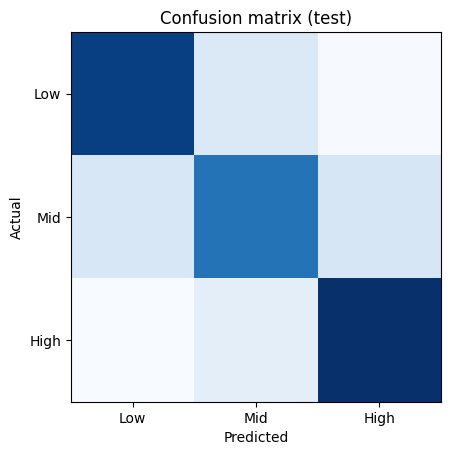

In [36]:
cm = confusion_matrix(c_test, pred_c)
print(pd.DataFrame(cm, index=['실제 적음', '실제 보통', '실제 많음'],
                   columns=['예측 적음', '예측 보통', '예측 많음']))

plt.imshow(cm, cmap='Blues')
plt.xticks([0, 1, 2], ['Low', 'Mid', 'High'])
plt.yticks([0, 1, 2], ['Low', 'Mid', 'High'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix (test)')
plt.show()

## 9. 시연 : 조건을 넣으면 대여량 예측

**하는 일** : 날씨·시간 조건을 모델에 넣을 수 있는 한 줄짜리 표로 만든다

**설명**
- 사용자는 시간, 기온, 습도, 풍속, 강수·적설량, 계절, 공휴일, 요일만 넣는다
- 나머지(주말·출퇴근·비 여부)는 3장과 같은 규칙으로 자동 계산한다
- 이슬점은 기온과 습도로 계산하는 근사식을 쓰고, 시정은 맑은 날 값(2000)으로 둔다

In [37]:
def make_row(hour, temp, humidity, wind, rain, snow, season, holiday, weekday, solar=0.0):
    row = {'Hour': hour, 'Temp': temp, 'Humidity': humidity, 'Wind': wind,
           'Visibility': 2000,
           'Dew': temp - (100 - humidity) / 5,     # 이슬점 근사식
           'Solar': solar, 'Rain': rain, 'Snow': snow,
           'Season': season, 'Holiday': holiday,
           'Weekend': 1 if weekday >= 5 else 0,
           'Commute': commute.get(hour, 0),
           'Rainy': 1 if rain > 0 else 0}
    return pd.DataFrame([row])

**하는 일** : 최적 회귀·분류 모델과 로지스틱 회귀로 예측 결과를 보여 준다

**설명**
- 대여량 : 8장에서 찾은 최적 회귀 모델 (음수가 나오면 0으로)
- 수요 단계 : 8장에서 찾은 최적 분류 모델
- 단계별 확률 : 7장 로지스틱 회귀의 `predict_proba` (실습 weatherHistory 방식)
- 학습 때와 **같은 scaler**로 바꿔야 올바른 예측이 나온다

In [38]:
level_names = ['적음', '보통', '많음']

def predict_demand(hour, temp, humidity, wind, rain, snow, season, holiday, weekday, solar=0.0):
    row = make_row(hour, temp, humidity, wind, rain, snow, season, holiday, weekday, solar)

    Xr = row[best_cols_r]
    if best_reg_scaler is not None:
        Xr = best_reg_scaler.transform(Xr)
    count = best_reg.predict(Xr)[0]

    Xc = row[best_cols_c]
    if best_cls_scaler is not None:
        Xc = best_cls_scaler.transform(Xc)
    level = best_cls.predict(Xc)[0]

    proba = logi.predict_proba(base_scaler.transform(row[base_cols]))[0]

    print(f'예상 대여량 : {max(count, 0):.0f}대')
    print(f'수요 단계   : {level_names[level]}')
    print(f'단계별 확률 : 적음 {proba[0]:.0%} / 보통 {proba[1]:.0%} / 많음 {proba[2]:.0%}')

**하는 일** : 세 가지 상황을 넣어 본다

**설명**
- 계절 : 봄 0, 여름 1, 가을 2, 겨울 3 / 요일 : 월 0 ~ 일 6

In [39]:
print('① 여름 평일 퇴근길 (18시, 25도, 맑음)')
predict_demand(hour=18, temp=25, humidity=50, wind=2.0, rain=0, snow=0,
               season=1, holiday=0, weekday=2, solar=0.5)

print('\n② 겨울 주말 새벽 (5시, -8도)')
predict_demand(hour=5, temp=-8, humidity=40, wind=1.5, rain=0, snow=0,
               season=3, holiday=0, weekday=6)

print('\n③ 가을 평일 출근길에 비 (8시, 15도, 비 5mm)')
predict_demand(hour=8, temp=15, humidity=90, wind=3.0, rain=5, snow=0,
               season=2, holiday=0, weekday=1, solar=0.1)

① 여름 평일 퇴근길 (18시, 25도, 맑음)
예상 대여량 : 2870대
수요 단계   : 많음
단계별 확률 : 적음 0% / 보통 5% / 많음 95%

② 겨울 주말 새벽 (5시, -8도)
예상 대여량 : 37대
수요 단계   : 적음
단계별 확률 : 적음 94% / 보통 6% / 많음 0%

③ 가을 평일 출근길에 비 (8시, 15도, 비 5mm)
예상 대여량 : 132대
수요 단계   : 적음
단계별 확률 : 적음 88% / 보통 11% / 많음 0%


## 10. 결론

> 실행 결과를 보고 채우기

- **Q1. 언제 많이 탈까?** : (예: 평일 출퇴근 시간, 여름·가을 …)
- **Q2. 어떤 날씨가 영향을 줄까?** : (예: 기온이 가장 큰 +영향, 비가 오면 크게 감소 …)
- **Q3. 얼마나 정확히 예측할까?** : 선형회귀 R² (  ) → 자동 탐색 최적 모델 R² (  ), 분류 정확도 (  )
- **한계** : (예: 대여량이 아주 많은 시간대를 덜 맞힘, 1년치 데이터만 사용 …)
- **활용 제안** : (예: 출퇴근 전 자전거 재배치, 비 예보 시 정비 일정 …)

## 11. 생성형 AI 활용 기록

| 단계 | 사용 도구 | 입력한 프롬프트 (요약) | AI 결과 | 우리가 검증·수정한 것 |
|---|---|---|---|---|
| 주제 선정 | Claude | "수업에서 배운 범위 안에서 할 수 있는 데이터마이닝 주제 추천해줘" | 따릉이 수요 예측 추천 | 데이터를 직접 열어 결측치·인코딩 확인 |
| 노트북 뼈대 | Claude | "따릉이 데이터로 수업 범위만 써서 코랩 노트북 뼈대 만들어줘" | 노트북 초안 | 실습에 없는 함수(heatmap, corr 등)를 찾아 실습 함수로 교체 |
| (추가) | | | | |